In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 150
matplotlib.rcParams['font.size'] = 10

df_all = pd.read_csv("results/all_results.csv")
print(df_all.columns.tolist())
print(f"Toplam satır: {len(df_all)}")
print(df_all.to_string(index=False))

['model', 'experiment', 'accuracy', 'f1_score', 'model_size_mb', 'energy_kwh', 'training_time_s', 'co2_kg', 'parameters', 'inference_time_s', 'mae', 'rmse']
Toplam satır: 13
      model                             experiment  accuracy  f1_score  model_size_mb  energy_kwh  training_time_s   co2_kg  parameters  inference_time_s     mae    rmse
MobileNetV2              Baseline (Early Stopping)    0.6547    0.6522         9.2700    0.008409          1038.72 0.003907         NaN               NaN     NaN     NaN
MobileNetV2                    Quantization (INT8)    0.6286    0.6253         2.6000    0.000120            19.93 0.000056         NaN               NaN     NaN     NaN
MobileNetV2                 Pruning (%50 Sparsity)    0.6441    0.6420         9.1600    0.002912           377.24 0.001353         NaN               NaN     NaN     NaN
MobileNetV2 Pruning v2 (%50 Sparsity - Full Model)    0.8406    0.8405         9.1600    0.016224          1584.48 0.007538         NaN           

In [23]:
print(df.columns.tolist())
print(df[df['model'] == 'LSTM'])

['model', 'experiment', 'accuracy', 'f1_score', 'model_size_mb', 'energy_kwh', 'training_time_s', 'co2_kg', 'parameters', 'inference_time_s', 'short_exp']
Empty DataFrame
Columns: [model, experiment, accuracy, f1_score, model_size_mb, energy_kwh, training_time_s, co2_kg, parameters, inference_time_s, short_exp]
Index: []


In [5]:
# Veri Normalizasyonu
df_mob = pd.read_csv("../results/mobilenet_results.csv")
df_dis = pd.read_csv("results/distilbert_results.csv")

# Ortak şemaya dönüştür
def normalize_mobilenet(df):
    return pd.DataFrame({
        'model': df['Model'],
        'experiment': df['Teknik'],
        'accuracy': df['Accuracy'],
        'f1_score': df['F1'],
        'model_size_mb': df['Model Boyutu (MB)'],
        'energy_kwh': df['Enerji (kWh)'],
        'training_time_s': df['Eğitim Süresi (sn)'],
        'co2_kg': df['CO2 (kg)'],
        # MobileNet'te olmayan sütunlar
        'parameters': None,
        'inference_time_s': None,
    })

def normalize_distilbert(df):
    return pd.DataFrame({
        'model': df['model'],
        'experiment': df['experiment'],
        'accuracy': df['accuracy'],
        'f1_score': df['f1_score'],
        'model_size_mb': df['model_size_mb'],
        'energy_kwh': df['energy_kwh'],
        'training_time_s': None,  # DistilBERT'te yok
        'co2_kg': None,
        'parameters': df['parameters'],
        'inference_time_s': df['inference_time_s'],
    })

df_m = normalize_mobilenet(df_mob)
df_d = normalize_distilbert(df_dis)
df = pd.concat([df_m, df_d], ignore_index=True)

# Temiz all_results üzerine yaz
df.to_csv("../results/all_results.csv", index=False)
print(df.to_string(index=False))

      model                             experiment  accuracy  f1_score  model_size_mb  energy_kwh training_time_s    co2_kg parameters inference_time_s
MobileNetV2              Baseline (Early Stopping)    0.6547    0.6522           9.27    0.008409         1038.72  0.003907       None             None
MobileNetV2                    Quantization (INT8)    0.6286    0.6253           2.60    0.000120           19.93  0.000056       None             None
MobileNetV2                 Pruning (%50 Sparsity)    0.6441    0.6420           9.16    0.002912          377.24  0.001353       None             None
MobileNetV2 Pruning v2 (%50 Sparsity - Full Model)    0.8406    0.8405           9.16    0.016224         1584.48  0.007538       None             None
MobileNetV2                   Baseline (Unfreezed)    0.8638    0.8640          26.34    0.021275         2398.31  0.009884       None             None
 DistilBERT                     Baseline (3 epoch)    0.8589    0.8588         255.42   

In [6]:
# Renk & Stil Ayarları

COLOR_MOB = '#2196F3'
COLOR_DIS = '#FF7043'
COLOR_MOB_LIGHT = '#90CAF9'
COLOR_DIS_LIGHT = '#FFAB91'

def model_color(model_name):
    return COLOR_MOB if 'mobile' in str(model_name).lower() else COLOR_DIS

def short_label(experiment):
    """Uzun deney adlarını grafikler için kısalt"""
    replacements = {
        'Baseline (Early Stopping)': 'Baseline (ES)',
        'Quantization (INT8)': 'Quant INT8',
        'Pruning (%50 Sparsity)': 'Pruning %50',
        'Pruning v2 (%50 Sparsity - Full Model)': 'Pruning v2 Full',
        'Baseline (Unfreezed)': 'Baseline (Unf)',
        'Baseline (3 epoch)': 'Baseline 3ep',
        'Dynamic Quantization INT8': 'Dyn Quant INT8',
        'Structured Pruning 33% + 1ep recovery': 'Struct Pruning 33%',
        'Early Stopping (stopped ep 2)': 'Early Stop ep2',
    }
    return replacements.get(experiment, experiment)

df['short_exp'] = df['experiment'].apply(short_label)

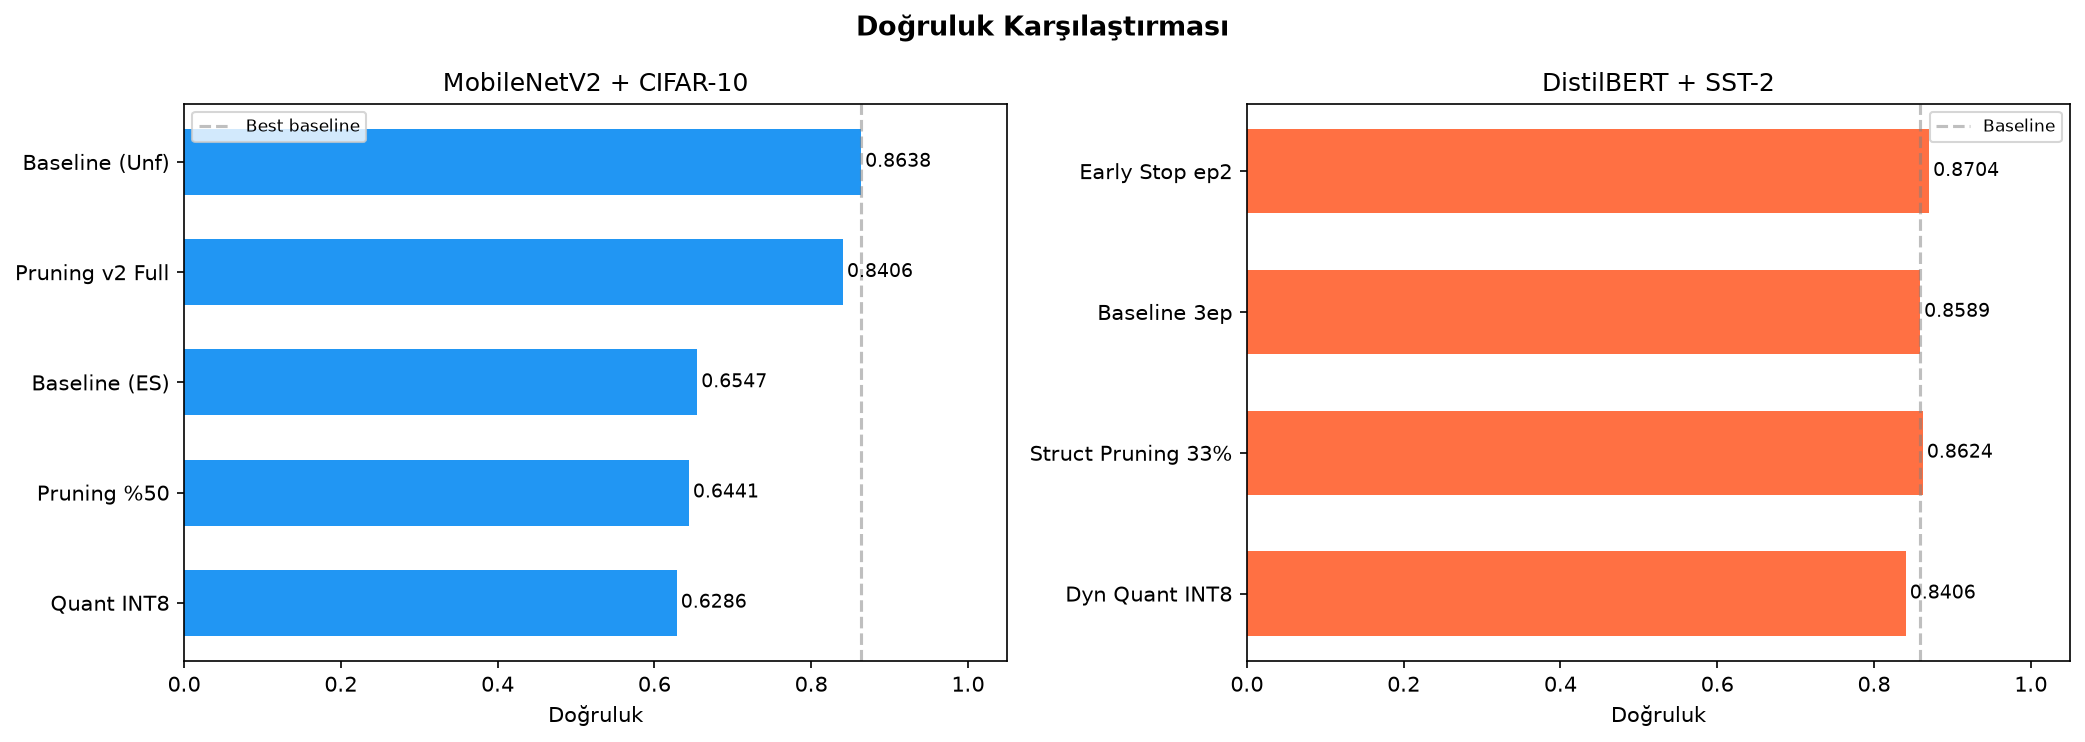

In [7]:
# Grafik 1: Doğruluk Karşılaştırması (Model Bazında)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Doğruluk Karşılaştırması", fontsize=13, fontweight='bold')

# MobileNetV2
dm = df[df['model'] == 'MobileNetV2'].sort_values('accuracy', ascending=True)
bars1 = ax1.barh(dm['short_exp'], dm['accuracy'], color=COLOR_MOB, height=0.6)
for bar, val in zip(bars1, dm['accuracy']):
    ax1.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)
ax1.set_xlim(0, 1.05)
ax1.set_xlabel('Doğruluk')
ax1.set_title('MobileNetV2 + CIFAR-10')
ax1.axvline(x=dm[dm['experiment'].str.contains('Unfreezed')]['accuracy'].values[0],
            color='gray', linestyle='--', alpha=0.5, label='Best baseline')
ax1.legend(fontsize=8)

# DistilBERT
dd = df[df['model'] == 'DistilBERT'].sort_values('model_size_mb', ascending=True)
bars2 = ax2.barh(dd['short_exp'], dd['accuracy'], color=COLOR_DIS, height=0.6)
for bar, val in zip(bars2, dd['accuracy']):
    ax2.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=9)
ax2.set_xlim(0, 1.05)
ax2.set_xlabel('Doğruluk')
ax2.set_title('DistilBERT + SST-2')
ax2.axvline(x=dd[dd['experiment'].str.contains('Baseline')].iloc[0]['accuracy'],
            color='gray', linestyle='--', alpha=0.5, label='Baseline')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/01_dogruluk_karsilastirma.png", bbox_inches='tight', dpi=200)
plt.show()

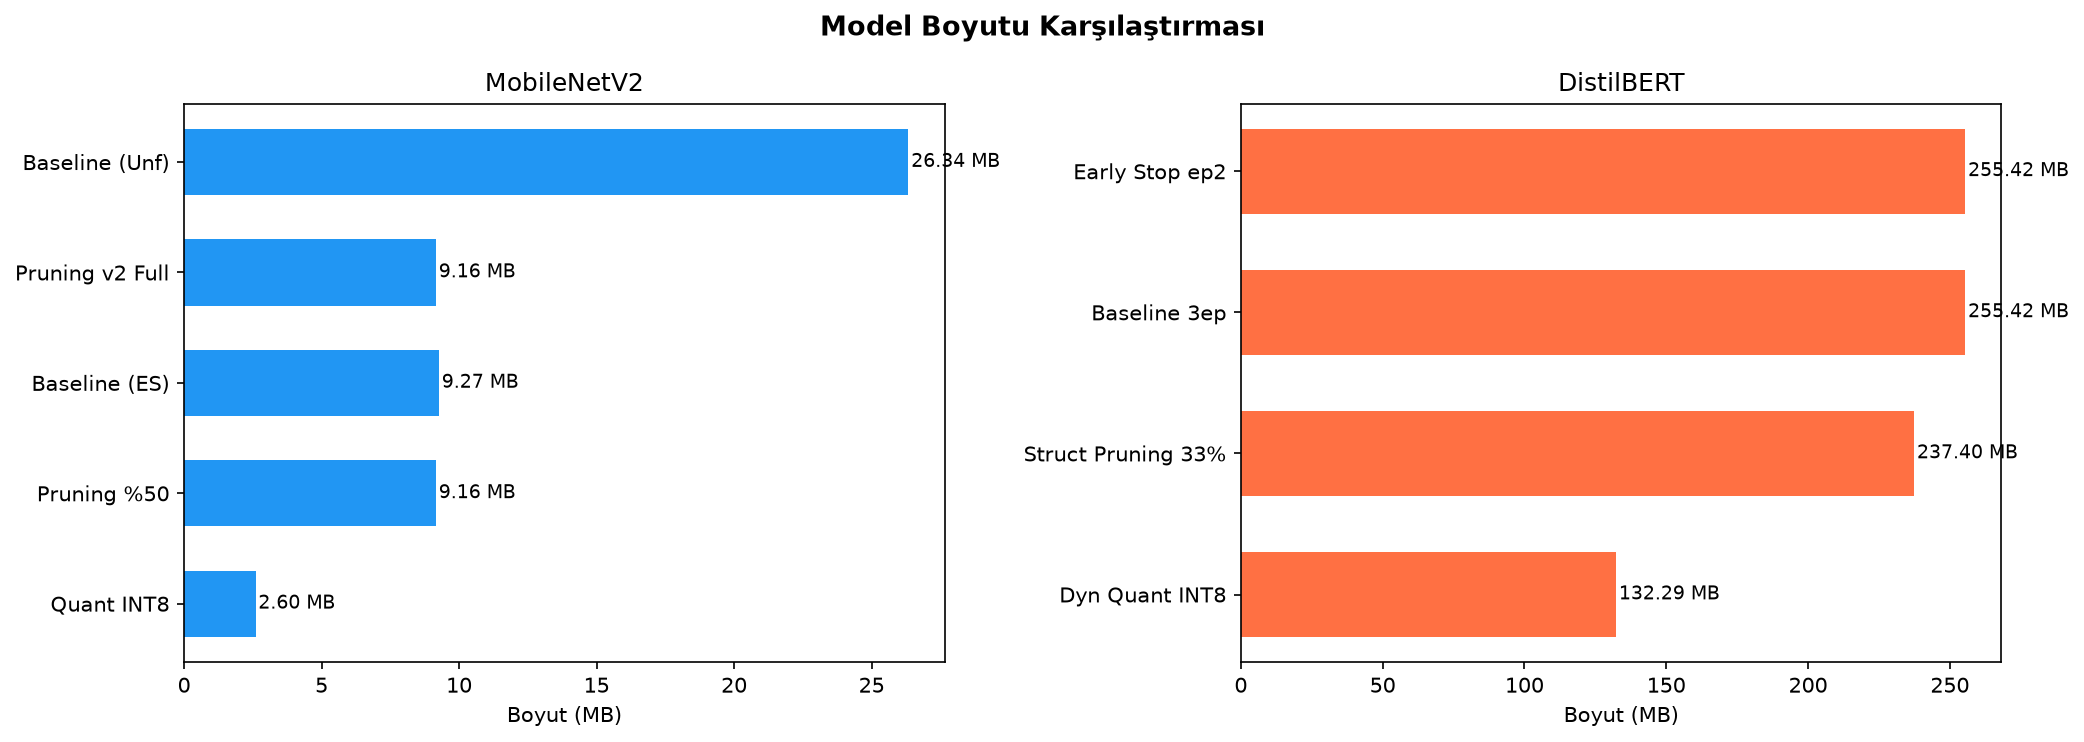

In [8]:
# Grafik 2: Model Boyutu Karşılaştırması

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Model Boyutu Karşılaştırması", fontsize=13, fontweight='bold')

# MobileNetV2
dm_energy = df[(df['model'] == 'MobileNetV2') & 
               (~df['experiment'].str.contains('Quantization'))]
bars1 = ax1.barh(dm['short_exp'], dm['model_size_mb'], color=COLOR_MOB, height=0.6)
for bar, val in zip(bars1, dm['model_size_mb']):
    ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{val:.2f} MB', va='center', fontsize=9)
ax1.set_xlabel('Boyut (MB)')
ax1.set_title('MobileNetV2')

# DistilBERT
dd = df[df['model'] == 'DistilBERT'].sort_values('model_size_mb', ascending=True)
bars2 = ax2.barh(dd['short_exp'], dd['model_size_mb'], color=COLOR_DIS, height=0.6)
for bar, val in zip(bars2, dd['model_size_mb']):
    ax2.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
             f'{val:.2f} MB', va='center', fontsize=9)
ax2.set_xlabel('Boyut (MB)')
ax2.set_title('DistilBERT')

plt.tight_layout()
plt.savefig("results/02_model_boyutu.png", bbox_inches='tight', dpi=200)
plt.show()

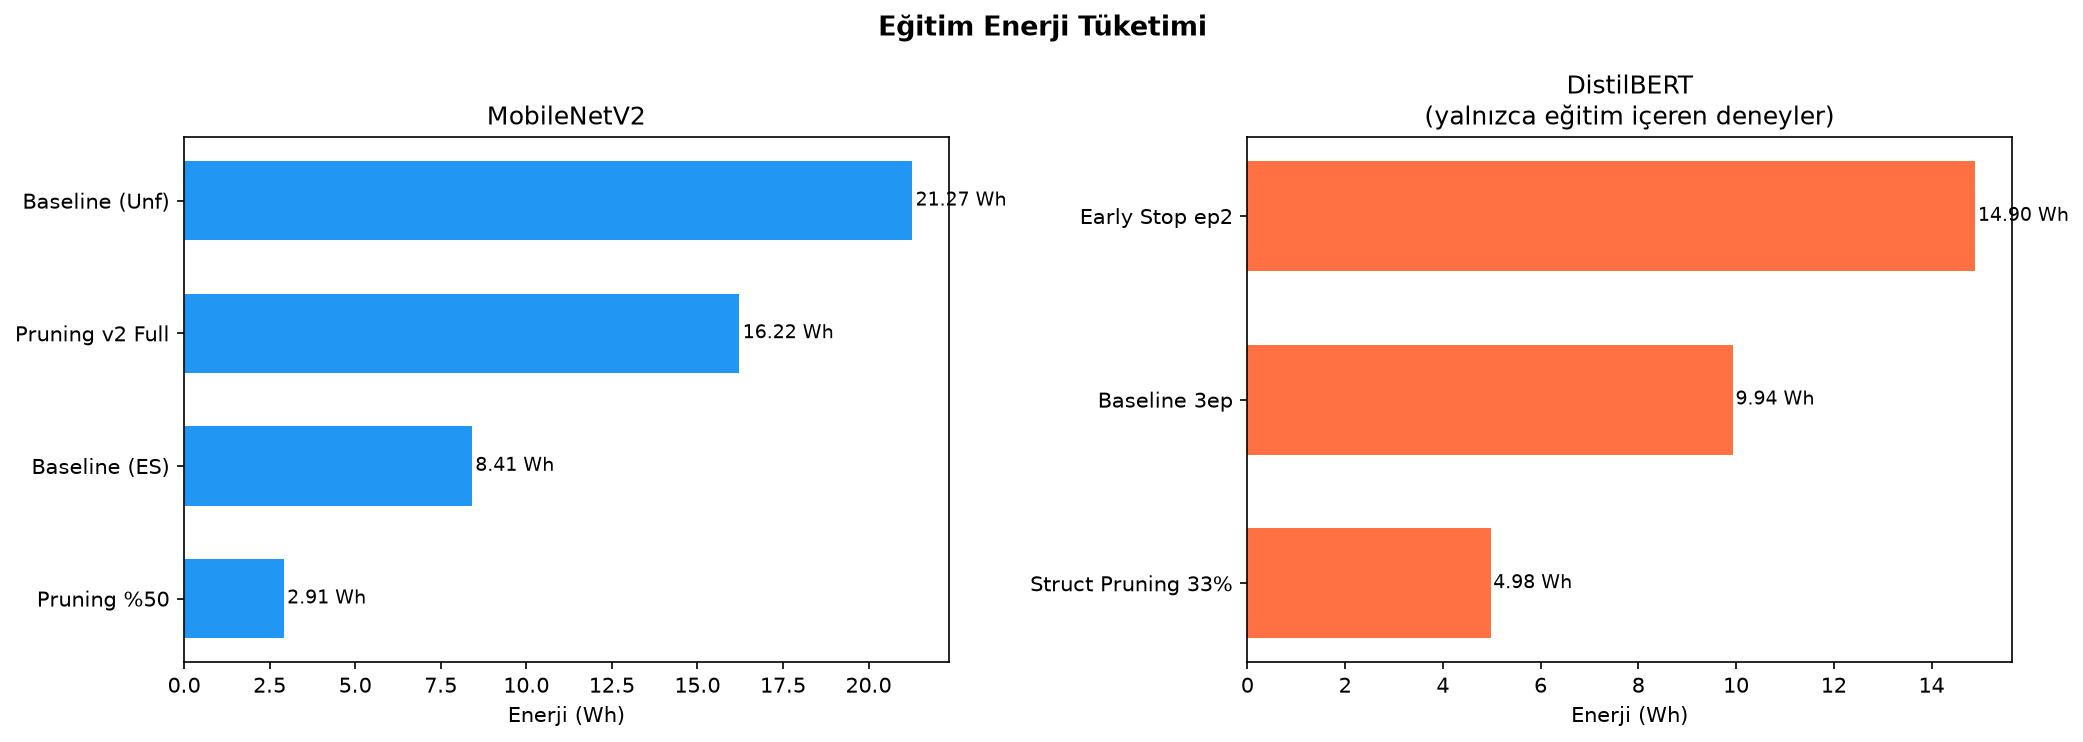

In [9]:
# Grafik 3: Enerji Tüketimi Karşılaştırması

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Eğitim Enerji Tüketimi", fontsize=13, fontweight='bold')

# MobileNet — tüm deneyler eğitim içeriyor
dm = df[(df['model'] == 'MobileNetV2') & 
        (~df['experiment'].str.contains('Quantization'))].sort_values('energy_kwh', ascending=True)
bars1 = ax1.barh(dm['short_exp'], dm['energy_kwh'] * 1000, color=COLOR_MOB, height=0.6)
for bar, val in zip(bars1, dm['energy_kwh']):
    ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{val*1000:.2f} Wh', va='center', fontsize=9)
ax1.set_xlabel('Enerji (Wh)')
ax1.set_title('MobileNetV2')

# DistilBERT — sadece eğitim içerenler (quantization hariç)
dd_energy = df[(df['model'] == 'DistilBERT') & (df['energy_kwh'] > 0.001)]
dd_energy = dd_energy.sort_values('energy_kwh', ascending=True)
bars2 = ax2.barh(dd_energy['short_exp'], dd_energy['energy_kwh'] * 1000, 
                 color=COLOR_DIS, height=0.6)
for bar, val in zip(bars2, dd_energy['energy_kwh']):
    ax2.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
             f'{val*1000:.2f} Wh', va='center', fontsize=9)
ax2.set_xlabel('Enerji (Wh)')
ax2.set_title('DistilBERT\n(yalnızca eğitim içeren deneyler)')

plt.tight_layout()
plt.savefig("results/03_enerji_tuketimi.png", bbox_inches='tight', dpi=200)
plt.show()

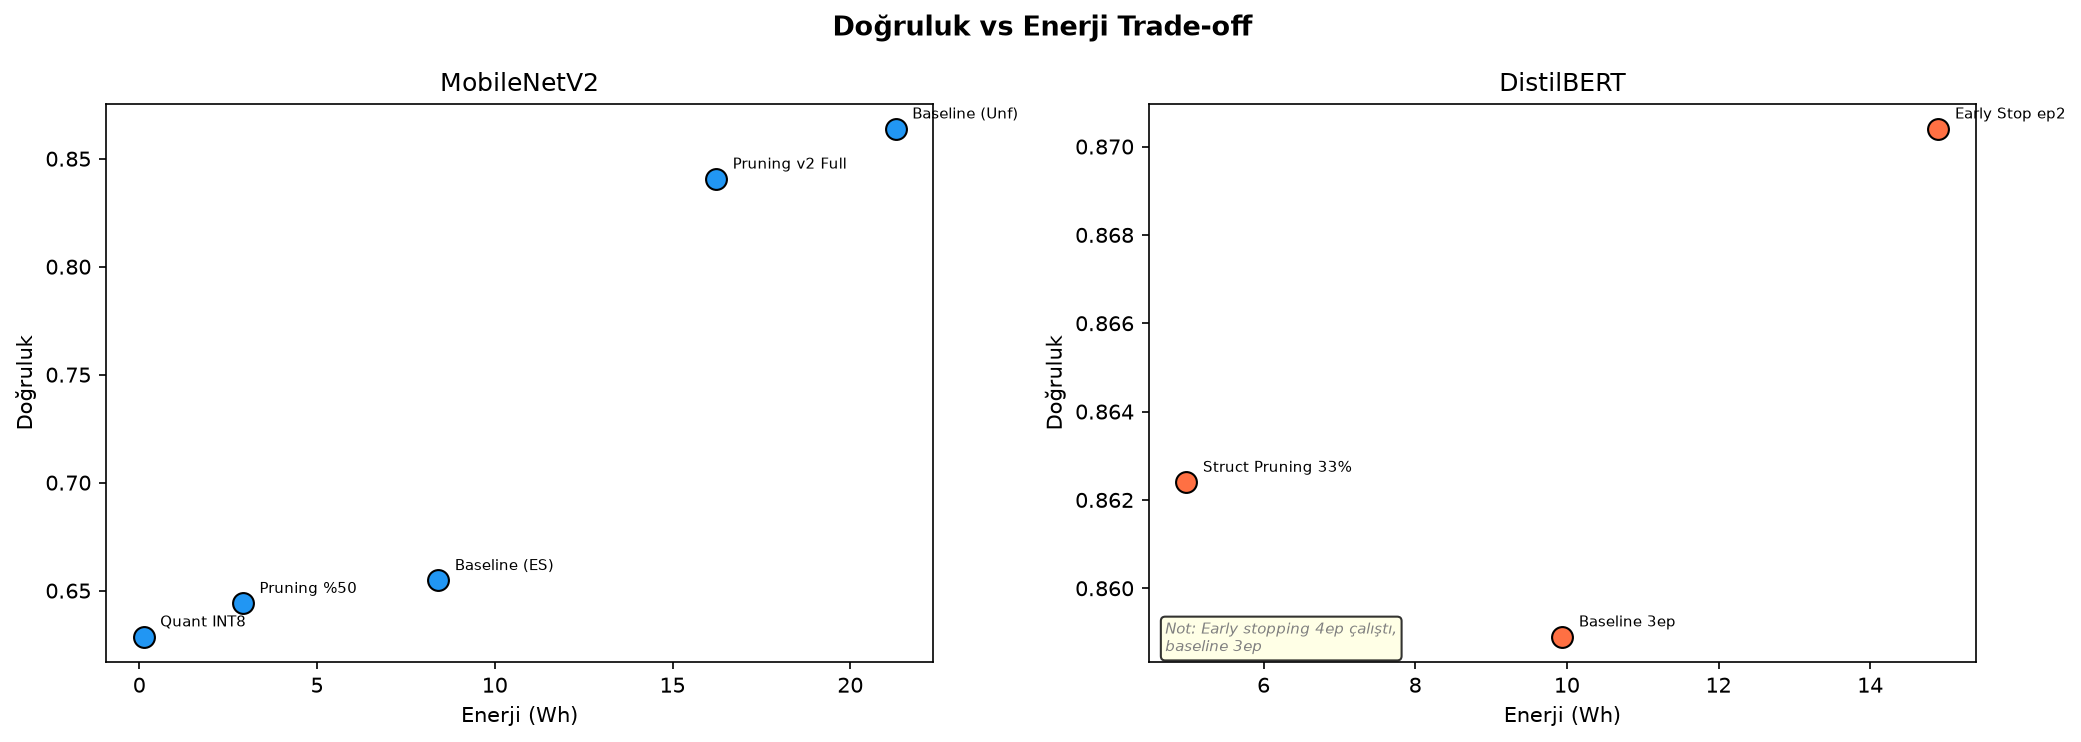

In [10]:
# Grafik 4: Doğruluk vs Enerji Tradeoff

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Doğruluk vs Enerji Trade-off", fontsize=13, fontweight='bold')

# MobileNet
dm = df[df['model'] == 'MobileNetV2']
ax1.scatter(dm['energy_kwh'] * 1000, dm['accuracy'], 
            c=COLOR_MOB, s=100, zorder=5, edgecolors='black')
for _, row in dm.iterrows():
    ax1.annotate(row['short_exp'], 
                 (row['energy_kwh'] * 1000, row['accuracy']),
                 textcoords="offset points", xytext=(8, 5), fontsize=7)
ax1.set_xlabel('Enerji (Wh)')
ax1.set_ylabel('Doğruluk')
ax1.set_title('MobileNetV2')

# DistilBERT — sadece eğitim içerenler
dd = df[(df['model'] == 'DistilBERT') & (df['energy_kwh'] > 0.001)]
ax2.scatter(dd['energy_kwh'] * 1000, dd['accuracy'],
            c=COLOR_DIS, s=100, zorder=5, edgecolors='black')
for _, row in dd.iterrows():
    ax2.annotate(row['short_exp'],
                 (row['energy_kwh'] * 1000, row['accuracy']),
                 textcoords="offset points", xytext=(8, 5), fontsize=7)
ax2.set_xlabel('Enerji (Wh)')
ax2.set_ylabel('Doğruluk')
ax2.set_title('DistilBERT')
ax2.annotate('Not: Early stopping 4ep çalıştı,\nbaseline 3ep',
             xy=(0.02, 0.02), xycoords='axes fraction',
             fontsize=7, style='italic', color='gray',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.savefig("results/04_dogruluk_vs_enerji.png", bbox_inches='tight', dpi=200)
plt.show()

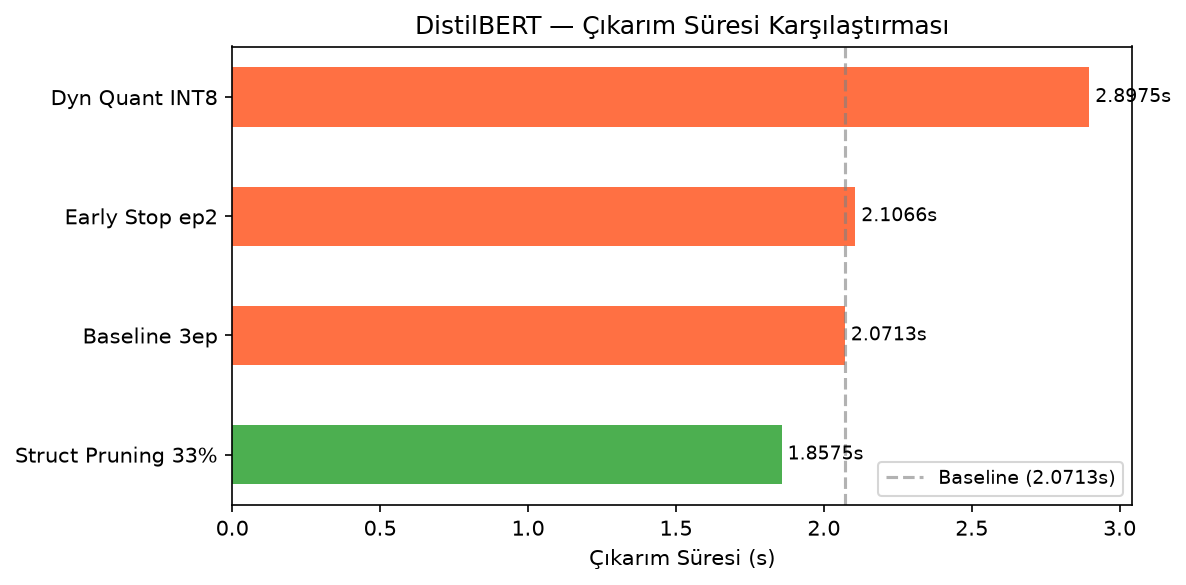

In [11]:
# Grafik 5: DistilBERT Çıkarım Süresi

fig, ax = plt.subplots(figsize=(8, 4))

dd_inf = df[(df['model'] == 'DistilBERT') & (df['inference_time_s'].notna())]
dd_inf = dd_inf.sort_values('inference_time_s', ascending=True)

colors = [COLOR_DIS if val > dd_inf['inference_time_s'].min() else '#4CAF50' 
          for val in dd_inf['inference_time_s']]
bars = ax.barh(dd_inf['short_exp'], dd_inf['inference_time_s'], 
               color=colors, height=0.5)
for bar, val in zip(bars, dd_inf['inference_time_s']):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}s', va='center', fontsize=9)

baseline_val = dd_inf[dd_inf['experiment'].str.contains('Baseline')]['inference_time_s']
if len(baseline_val) > 0:
    ax.axvline(x=baseline_val.values[0], color='gray', linestyle='--', 
               alpha=0.6, label=f'Baseline ({baseline_val.values[0]:.4f}s)')
    ax.legend(fontsize=9)

ax.set_xlabel('Çıkarım Süresi (s)')
ax.set_title('DistilBERT — Çıkarım Süresi Karşılaştırması')
plt.tight_layout()
plt.savefig("results/05_inference_suresi.png", bbox_inches='tight', dpi=200)
plt.show()

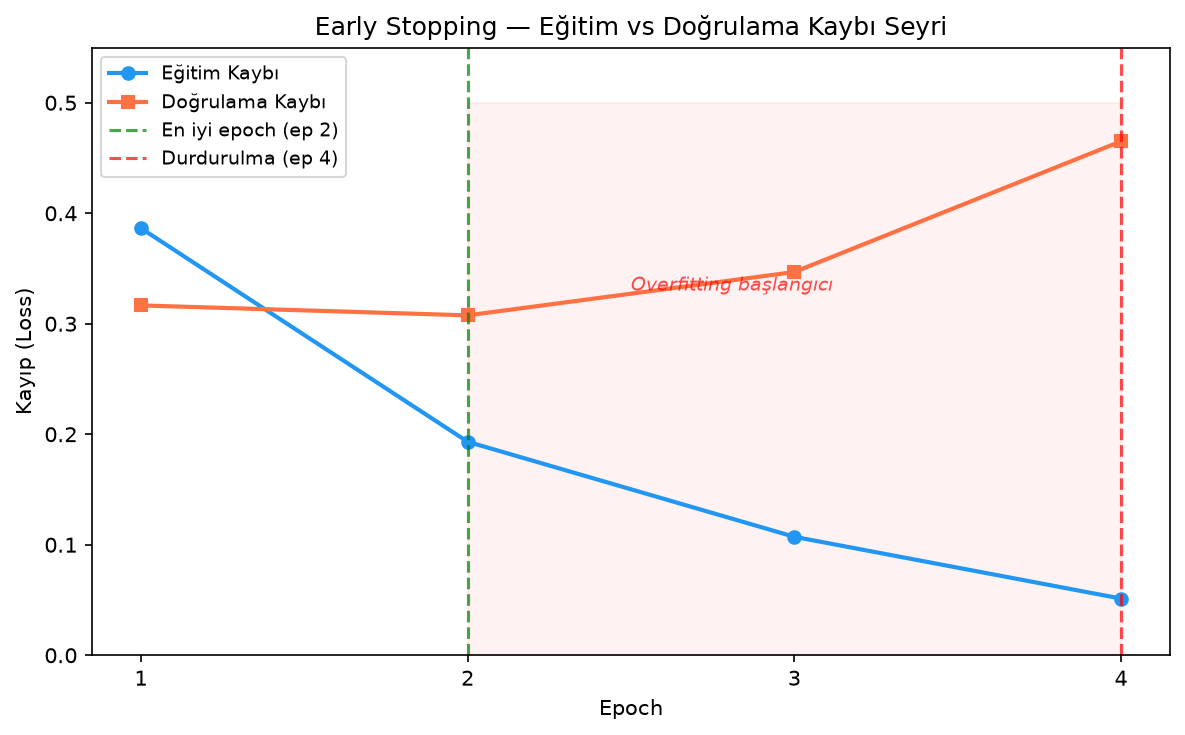

In [12]:
# Grafik 6: Early Stopping Eğitim Seyri

fig, ax = plt.subplots(figsize=(8, 5))

epochs = [1, 2, 3, 4]
train_loss = [0.3865, 0.1932, 0.1072, 0.0513]
val_loss = [0.3166, 0.3076, 0.3468, 0.4651]
accuracy = [0.8555, 0.8704, 0.8647, 0.8761]

ax.plot(epochs, train_loss, 'o-', color=COLOR_MOB, label='Eğitim Kaybı', linewidth=2)
ax.plot(epochs, val_loss, 's-', color=COLOR_DIS, label='Doğrulama Kaybı', linewidth=2)

# Overfitting bölgesi
ax.fill_between([2, 4], 0, 0.5, color='red', alpha=0.05)
ax.axvline(x=2, color='green', linestyle='--', alpha=0.7, label='En iyi epoch (ep 2)')
ax.axvline(x=4, color='red', linestyle='--', alpha=0.7, label='Durdurulma (ep 4)')

ax.annotate('Overfitting başlangıcı', xy=(2.5, 0.33), fontsize=9,
            color='red', alpha=0.7, style='italic')

ax.set_xlabel('Epoch')
ax.set_ylabel('Kayıp (Loss)')
ax.set_title('Early Stopping — Eğitim vs Doğrulama Kaybı Seyri')
ax.legend(fontsize=9)
ax.set_xticks(epochs)
ax.set_ylim(0, 0.55)

plt.tight_layout()
plt.savefig("results/06_early_stopping_seyri.png", bbox_inches='tight', dpi=200)
plt.show()

In [13]:
# Özet Tablo

print("TÜM DENEYLER — ÖZET TABLO")
print("=" * 90)

df_table = df[['model', 'experiment', 'accuracy', 'f1_score', 
               'model_size_mb', 'energy_kwh']].copy()
df_table['energy'] = df_table['energy_kwh'].apply(
    lambda x: f"{x*1000:.2f} Wh" if pd.notna(x) and x > 0.001 else "—"
)
df_table = df_table.drop(columns=['energy_kwh'])
df_table.columns = ['Model', 'Deney', 'Doğruluk', 'F1', 'Boyut (MB)', 'Enerji']
print(df_table.to_string(index=False))

TÜM DENEYLER — ÖZET TABLO
      Model                                  Deney  Doğruluk     F1  Boyut (MB)   Enerji
MobileNetV2              Baseline (Early Stopping)    0.6547 0.6522        9.27  8.41 Wh
MobileNetV2                    Quantization (INT8)    0.6286 0.6253        2.60        —
MobileNetV2                 Pruning (%50 Sparsity)    0.6441 0.6420        9.16  2.91 Wh
MobileNetV2 Pruning v2 (%50 Sparsity - Full Model)    0.8406 0.8405        9.16 16.22 Wh
MobileNetV2                   Baseline (Unfreezed)    0.8638 0.8640       26.34 21.27 Wh
 DistilBERT                     Baseline (3 epoch)    0.8589 0.8588      255.42  9.94 Wh
 DistilBERT              Dynamic Quantization INT8    0.8406 0.8404      132.29        —
 DistilBERT  Structured Pruning 33% + 1ep recovery    0.8624 0.8621      237.40  4.98 Wh
 DistilBERT          Early Stopping (stopped ep 2)    0.8704 0.8704      255.42 14.90 Wh


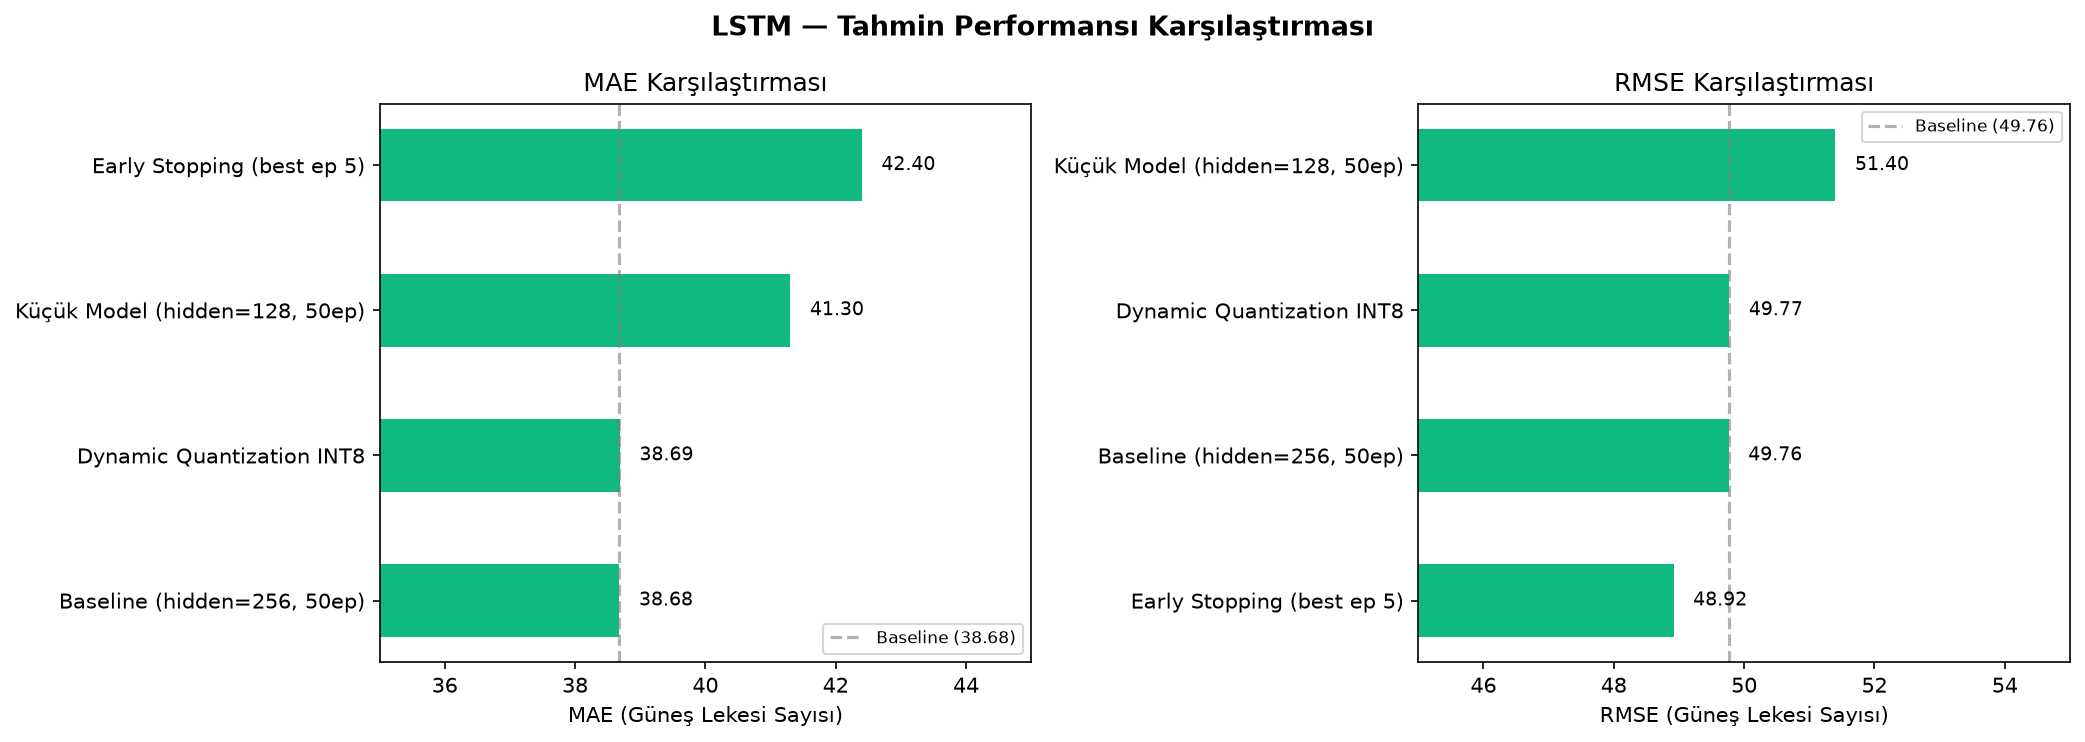

In [30]:
# LSTM: MAE/RMSE Karşılaştırması

df = pd.read_csv("results/all_results.csv")
df_lstm = df[df['model'] == 'LSTM'].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("LSTM — Tahmin Performansı Karşılaştırması", fontsize=13, fontweight='bold')

COLOR_LSTM = '#10B981'

# MAE
lstm_sorted = df_lstm.sort_values('mae', ascending=True)
bars1 = ax1.barh(lstm_sorted['experiment'], lstm_sorted['mae'], color=COLOR_LSTM, height=0.5)
for bar, val in zip(bars1, lstm_sorted['mae']):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=9)
baseline_mae = df_lstm[df_lstm['experiment'].str.contains('Baseline')]['mae'].values[0]
ax1.axvline(x=baseline_mae, color='gray', linestyle='--', alpha=0.6, label=f'Baseline ({baseline_mae:.2f})')
ax1.set_xlabel('MAE (Güneş Lekesi Sayısı)')
ax1.set_title('MAE Karşılaştırması')
ax1.set_xlim(35, 45)
ax1.legend(fontsize=8)

# RMSE
lstm_sorted_r = df_lstm.sort_values('rmse', ascending=True)
bars2 = ax2.barh(lstm_sorted_r['experiment'], lstm_sorted_r['rmse'], color=COLOR_LSTM, height=0.5)
for bar, val in zip(bars2, lstm_sorted_r['rmse']):
    ax2.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
             f'{val:.2f}', va='center', fontsize=9)
baseline_rmse = df_lstm[df_lstm['experiment'].str.contains('Baseline')]['rmse'].values[0]
ax2.axvline(x=baseline_rmse, color='gray', linestyle='--', alpha=0.6, label=f'Baseline ({baseline_rmse:.2f})')
ax2.set_xlabel('RMSE (Güneş Lekesi Sayısı)')
ax2.set_title('RMSE Karşılaştırması')
ax2.set_xlim(45, 55)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/07_lstm_performans.png", bbox_inches='tight', dpi=200)
plt.show()

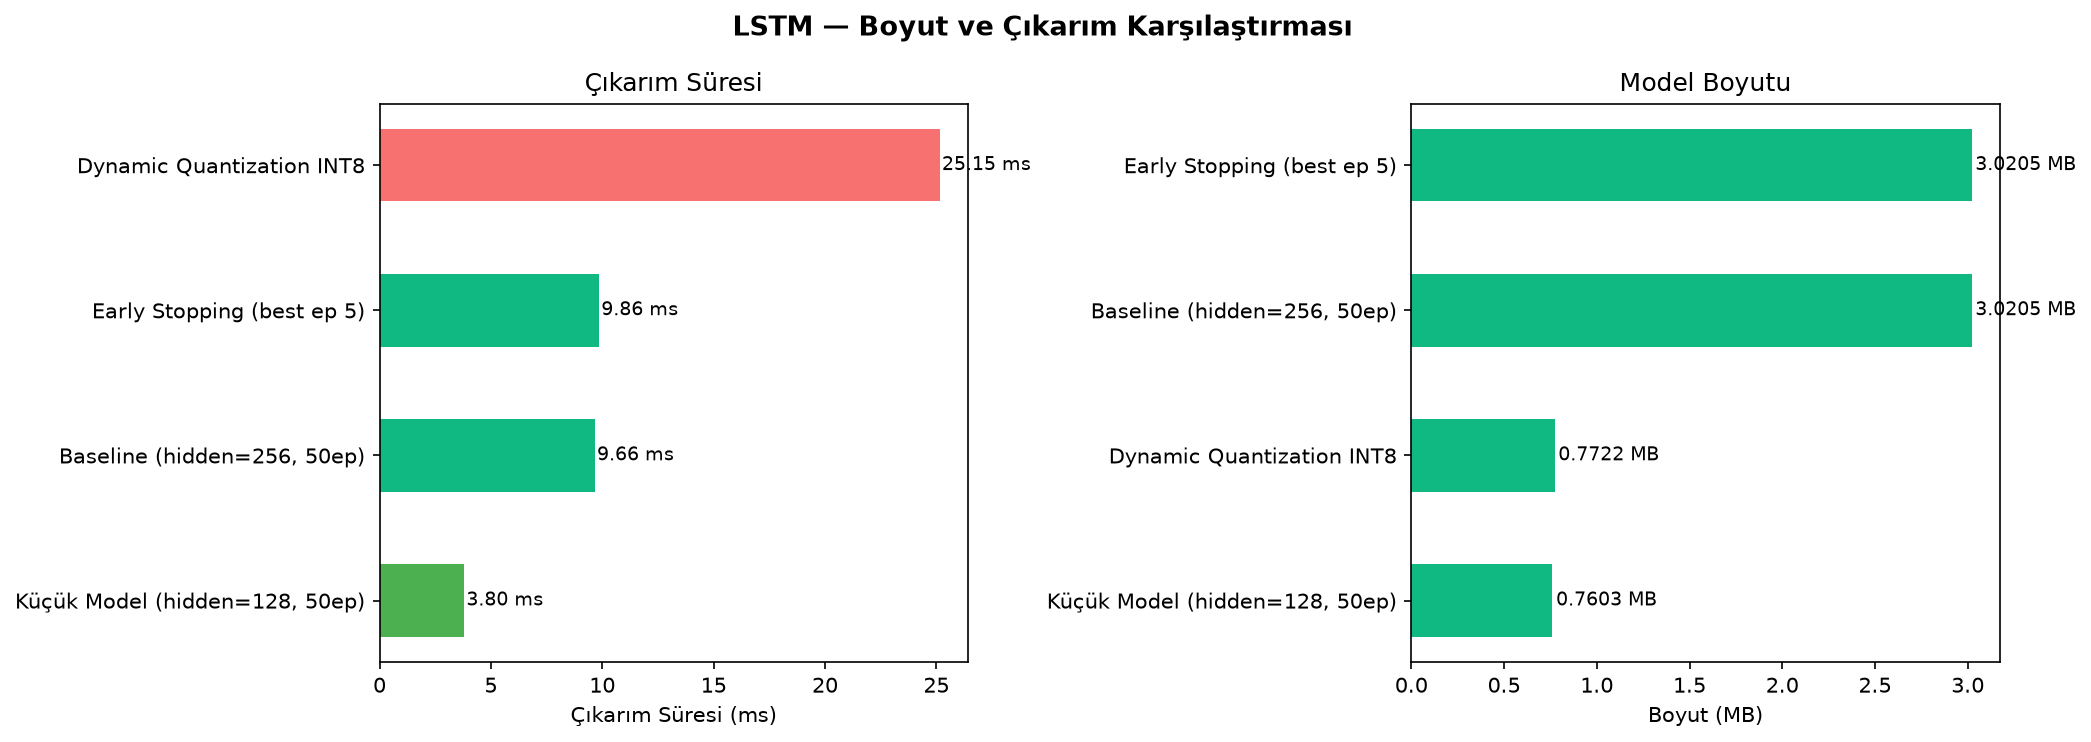

In [28]:
# LSTM: Çıkarım Süresi & Model Boyutu

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("LSTM — Boyut ve Çıkarım Karşılaştırması", fontsize=13, fontweight='bold')

COLOR_LSTM = '#10B981'

# Çıkarım süresi
lstm_inf = df_lstm.sort_values('inference_time_s', ascending=True)
colors_inf = [('#4CAF50' if val == lstm_inf['inference_time_s'].min() 
               else ('#F87171' if val == lstm_inf['inference_time_s'].max() 
               else COLOR_LSTM)) for val in lstm_inf['inference_time_s']]
bars1 = ax1.barh(lstm_inf['experiment'], lstm_inf['inference_time_s'] * 1000, 
                 color=colors_inf, height=0.5)
for bar, val in zip(bars1, lstm_inf['inference_time_s']):
    ax1.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{val*1000:.2f} ms', va='center', fontsize=9)
ax1.set_xlabel('Çıkarım Süresi (ms)')
ax1.set_title('Çıkarım Süresi')

# Model boyutu
lstm_size = df_lstm.sort_values('model_size_mb', ascending=True)
bars2 = ax2.barh(lstm_size['experiment'], lstm_size['model_size_mb'], color=COLOR_LSTM, height=0.5)
for bar, val in zip(bars2, lstm_size['model_size_mb']):
    ax2.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
             f'{val:.4f} MB', va='center', fontsize=9)
ax2.set_xlabel('Boyut (MB)')
ax2.set_title('Model Boyutu')

plt.tight_layout()
plt.savefig("results/08_lstm_boyut_cikarim.png", bbox_inches='tight', dpi=200)
plt.show()

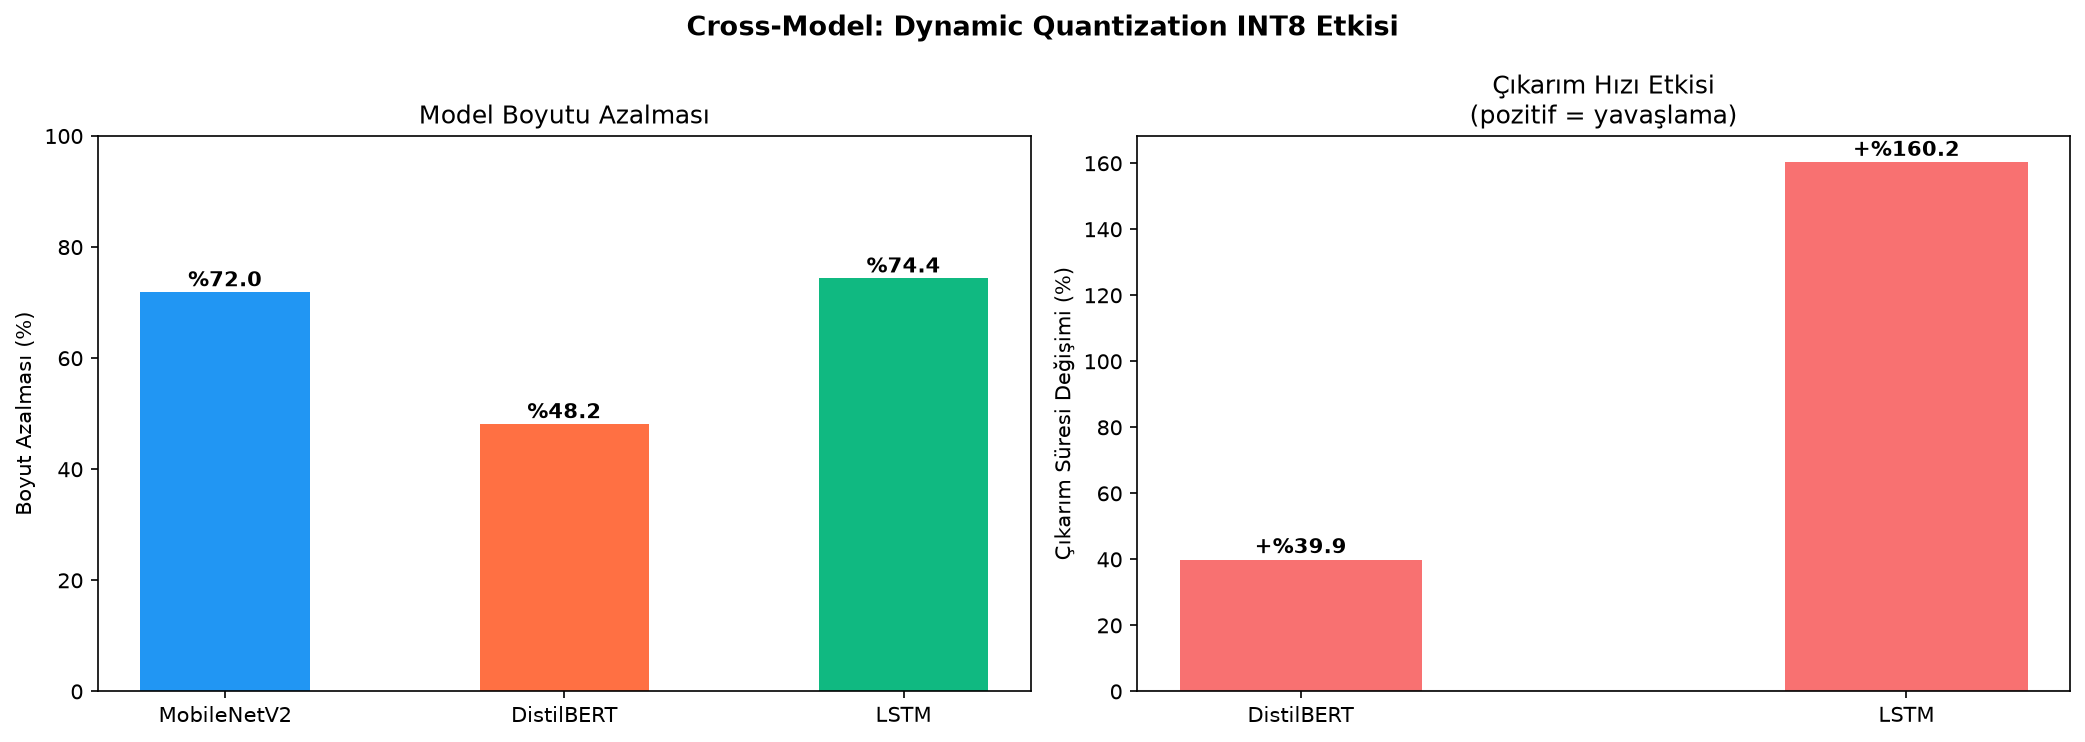

In [29]:
# Cross-Model: Quantization Etkisi (3 Model)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Cross-Model: Dynamic Quantization INT8 Etkisi", fontsize=13, fontweight='bold')

models = ['MobileNetV2', 'DistilBERT', 'LSTM']
colors = ['#2196F3', '#FF7043', '#10B981']

# Boyut azalması (%)
baseline_sizes = [9.27, 255.42, 3.0205]
quant_sizes = [2.60, 132.29, 0.7722]
reductions = [(1 - q/b) * 100 for b, q in zip(baseline_sizes, quant_sizes)]

bars1 = ax1.bar(models, reductions, color=colors, width=0.5)
for bar, val in zip(bars1, reductions):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
             f'%{val:.1f}', ha='center', fontsize=10, fontweight='bold')
ax1.set_ylabel('Boyut Azalması (%)')
ax1.set_title('Model Boyutu Azalması')
ax1.set_ylim(0, 100)

# Çıkarım hızı değişimi (%)
baseline_inf = [None, 2.0713, 0.009664]  # MobileNet'te inference yok
quant_inf = [None, 2.8975, 0.025149]
speed_change = []
labels = []
bar_colors = []
for i, (b, q) in enumerate(zip(baseline_inf, quant_inf)):
    if b is not None and q is not None:
        change = ((q - b) / b) * 100
        speed_change.append(change)
        labels.append(models[i])
        bar_colors.append('#F87171' if change > 0 else '#4ADE80')

bars2 = ax2.bar(labels, speed_change, color=bar_colors, width=0.4)
for bar, val in zip(bars2, speed_change):
    y_pos = bar.get_height() + 2 if val > 0 else bar.get_height() - 8
    ax2.text(bar.get_x() + bar.get_width()/2, y_pos,
             f'+%{val:.1f}' if val > 0 else f'%{val:.1f}', 
             ha='center', fontsize=10, fontweight='bold')
ax2.set_ylabel('Çıkarım Süresi Değişimi (%)')
ax2.set_title('Çıkarım Hızı Etkisi\n(pozitif = yavaşlama)')
ax2.axhline(y=0, color='gray', linestyle='-', alpha=0.3)

plt.tight_layout()
plt.savefig("results/09_cross_model_quantization.png", bbox_inches='tight', dpi=200)
plt.show()

In [31]:
import pandas as pd

df1 = pd.read_csv("results/all_results.csv")
print(f"results/all_results.csv: {len(df1)} satır, sütunlar: {df1.columns.tolist()}")

results/all_results.csv: 13 satır, sütunlar: ['model', 'experiment', 'accuracy', 'f1_score', 'model_size_mb', 'energy_kwh', 'training_time_s', 'co2_kg', 'parameters', 'inference_time_s', 'mae', 'rmse']
